# 자동차 부품 제조 공정 설명 키워드 분석
### 공정 설명 글에서 자주 나오는 제조 현장 키워드 찾기 — 정제 · 빈도 3종 비교 · 2-gram · 공정 단계 사전

**환경:** Google Colab (인터넷 연결 필요)
**준비물 (파일 1개)**
| 파일 | 내용 |
|---|---|
| 공정 설명 `.csv` 파일 | 자동차 부품 제조업 91개 공장의 공정 550개 (공장관리번호, 공정도명, 공정순서, **공정명**, **공정설명**) |

**소요 시간:** 약 40분

## 오늘의 상황
> 제조 현장에는 공정 설명서, 작업 지시서, 작업일지처럼 **글로 된 기록**이 많습니다.
> 이런 글에서 **자주 나오는 키워드**를 뽑으면, 현장에서 어떤 작업(입고·가공·조립·검사·포장)을 많이 하는지, 어떤 표현이 함께 쓰이는지 한눈에 볼 수 있습니다.



## 실습 진행 과정
| 단계 | 할 일 | 산출물 |
|---|---|---|
| 0. 준비 | 설치, `cp949`로 파일 읽기 | 원본 표 |
 | 1. 텍스트 전처리 | 반복 문구를 **열로 뽑고 본문에서 지우기** → 잘림·기호 정리 → 명사 뽑기 → 불용어·표기 통일 | 처리 전/후 비교 |
| 2. 정제 데이터셋 | 행별 키워드 저장, 사용장비·품질기준·특이사항 막대그래프 | `process_keywords.csv` |
| 3. 데이터 품질 점검 | 공정명과 설명 비교, 업종별 키워드 확인 | 점검 표 |
| 4. 키워드 분석 | **등장 횟수 vs 문서 빈도 vs TF-IDF**, 워드클라우드, 2-gram, 공정 단계 사전, 행별 대표 키워드 | 그래프 4개, 표 |
| 정리 | 한계 | — |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi (명사 뽑기) |
| `koreanize-matplotlib` | 그래프에 한글 글꼴(나눔고딕) 설정 |
| `wordcloud` | 워드클라우드 그리기 (Colab에 기본 설치) |
| `scikit-learn` | 단어 세기, TF-IDF (Colab에 기본 설치) |

In [1]:
# 도구 설치 (처음 한 번만 실행)
# !     : 파이썬 코드가 아니라 리눅스 명령어를 실행하라는 표시
# -q    : 설치 과정 메시지를 짧게 줄여서 보여 줌
!pip install -q kiwipiepy koreanize-matplotlib wordcloud

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 9.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 39.7 MB/s eta 0:00:00


> 🔧 다음 셀에서 `PIL` 관련 `ImportError`가 나면: 메뉴 **런타임 → 세션 다시 시작** 후 설치 셀은 건너뛰고 다음 셀부터 실행하세요.

Colab 왼쪽 **📁 파일 창**에 **공정 설명 `.csv` 파일**을 끌어다 놓으세요.

### 💡 `encoding="cp949"`는 왜 쓰나요?
공공기관·엑셀에서 내려받은 한글 CSV는 `cp949`(완성형 한글) 방식으로 저장된 경우가 많습니다. 이 파일도 `cp949`라서, 그냥 읽으면 `UnicodeDecodeError`가 납니다.

In [2]:
import glob                 # 파일 이름을 패턴(예: *.csv)으로 찾는 도구
import pandas as pd         # 표(DataFrame)를 다루는 도구

# 지금 폴더의 .csv 파일 중 이 실습에서 만드는 파일이 아닌 것 = 원본 파일
#   (다시 실행할 때 실습 결과 파일을 원본으로 잘못 고르지 않게 이름을 빼 둠)
raw_path = [p for p in glob.glob("*.csv") if p != "process_keywords.csv"][0]

# 원본 읽기 (encoding="cp949": 이 파일의 한글 저장 방식)
df = pd.read_csv(raw_path, encoding="cp949")

print("파일:", raw_path)
print("행 수:", len(df), "/ 공장 수:", df["공장관리번호"].nunique(), "/ 공정도명 종류:", df["공정도명"].nunique())

# 분석에 쓸 열만 앞 3줄 보기 (max_colwidth: 긴 글자를 80글자까지만 보이게)
pd.set_option("display.max_colwidth", 80)
df[["공정도명", "공정순서", "공정명", "공정설명"]].head(3)

파일: 한국산업단지공단_자동차 부품 제조업 공정 합성데이터_20250925.csv
행 수: 550 / 공장 수: 91 / 공정도명 종류: 25


,공정도명,공정순서,공정명,공정설명
0,자동차 내장 부품 제조업 생산공정,1,전처리,원재료 전처리 작업 수행 / 사용장비: 전처리장비 / 품질기준: 청결도 관리 / 특이사항: 정기점검 실시
1,자동차 조향장치 부품 제조업 생산공정,2,스프레이도장,CSP렙 제거 후 보드 배치(홀 가공기 위치) 알루미늄 프레임 삽입 홀가공 Gate 악세사리 조립(조립대 위치) 반사띠 부착 절단 파이프...
2,자동차 내장 부품 제조업 생산공정,3,사출성형,사출성형 작업 수행 / 사용장비: 산업용 장비 / 품질기준: 자동차 부품 기준 적용 / 특이사항: 온도 관리 중요


---
## 1. 텍스트 데이터 전처리

### 💡 처리 순서
| 순서 | 할 일 | 예 |
|---|---|---|
| 1-1 | 반복 문구를 **열로 뽑기** | `사용장비: 용접로봇` → `사용장비` 열에 `용접로봇` |
| 1-2 | 본문 정리 | 반복 문구·`작업 수행`·`...`·`gt`(깨진 기호)·숫자·기호 지우기 |
| 1-3 | 명사 뽑기 | Kiwi로 명사·외국어만 남기기 |
| 1-4 | 불용어·표기 통일 | `제품`, `공정`처럼 어디에나 나오는 말 빼기, `원재료`→`원자재` |

### 1-1. 반복 문구를 열로 뽑기
정규식 `사용장비:\s*([^/]+)`의 뜻:
- `사용장비:` 글자 그대로 찾고, `\s*` 뒤의 공백은 건너뜀
- `([^/]+)` `/`가 아닌 글자들을 **괄호로 묶어 꺼냄** (다음 `/` 앞까지)

In [3]:
import re                   # 정규식(글자 패턴 찾기·바꾸기) 도구

# 반복 문구 3종을 각각 새 열로 뽑기
#   str.extract(정규식): 괄호 ( ) 안에 맞는 글자를 꺼냄 → 없으면 NaN(빈 칸)
#   [0]: 꺼낸 결과 표의 첫 번째 열,  str.strip(): 앞뒤 공백 지우기
for col in ["사용장비", "품질기준", "특이사항"]:
    df[col] = df["공정설명"].str.extract(col + r":\s*([^/]+)")[0].str.strip()

print("반복 문구가 붙은 행:", df["사용장비"].notna().sum(), "/", len(df))
df.loc[df["사용장비"].notna(), ["공정설명", "사용장비", "품질기준", "특이사항"]].head(3)

반복 문구가 붙은 행: 234 / 550


,공정설명,사용장비,품질기준,특이사항
0,원재료 전처리 작업 수행 / 사용장비: 전처리장비 / 품질기준: 청결도 관리 / 특이사항: 정기점검 실시,전처리장비,청결도 관리,정기점검 실시
2,사출성형 작업 수행 / 사용장비: 산업용 장비 / 품질기준: 자동차 부품 기준 적용 / 특이사항: 온도 관리 중요,산업용 장비,자동차 부품 기준 적용,온도 관리 중요
7,유격 테스트 후 출고 원자래 투입 계량 / 포장 원재료 투입 계량 / Wheel Lo... 작업 수행 / 사용장비: 산업용 장비 / 품질...,산업용 장비,자동차 부품 기준 적용,습도 관리 필요


### 1-2. 본문 정리

In [4]:
# 글 하나 → 정리된 문장
def clean(text):
    text = re.sub(r"/\s*(사용장비|품질기준|특이사항):[^/]*", " ", text)   # 반복 문구 지우기 (이미 열로 뽑아 둠)
    text = re.sub(r"작업 수행", " ", text)                              # 반복 문구 앞에 붙던 말 지우기
    text = re.sub(r"\.\.\.|\bgt\b", " ", text)                         # 잘림 표시(...), 깨진 기호(&gt;의 gt) 지우기 (\b: 단어 경계)
    text = re.sub(r"[^가-힣A-Za-z]", " ", text)                          # 한글·영어가 아닌 글자(숫자, 기호, 괄호) → 공백
    return re.sub(r"\s+", " ", text).strip()                            # 여러 칸 공백을 한 칸으로, 앞뒤 공백 지우기

# 공정명과 공정설명을 이어 붙인 뒤 정리 → '문장' 열
df["원문"] = df["공정명"] + " " + df["공정설명"]
df["문장"] = df["원문"].apply(clean)

# 처리 전/후 비교 2개 (반복 문구가 있던 행)
for i in df[df["사용장비"].notna()].index[:2]:
    print("[처리 전]", df["원문"][i][:150])
    print("[처리 후]", df["문장"][i][:150])
    print()

[처리 전] 전처리 원재료 전처리 작업 수행 / 사용장비: 전처리장비 / 품질기준: 청결도 관리 / 특이사항: 정기점검 실시
[처리 후] 전처리 원재료 전처리

[처리 전] 사출성형 사출성형 작업 수행 / 사용장비: 산업용 장비 / 품질기준: 자동차 부품 기준 적용 / 특이사항: 온도 관리 중요
[처리 후] 사출성형 사출성형



### 1-3 · 1-4. 명사 뽑기 + 불용어 + 표기 통일
| 품사 | 기호 | 예 |
|---|---|---|
| 일반명사 | NNG | `검사`, `조립`, `용접` |
| 고유명사 | NNP | 회사 이름 등 |
| 외국어 | SL | `CNC`, `Tire`, `assy` |

**✏️ 불용어 `STOP`**: 거의 모든 공정 설명에 나와서 **구별에 도움이 안 되는 말**입니다. 결과를 보면서 고쳐 보세요.
**✏️ 표기 통일 `NORM`**: 같은 뜻의 다른 표현을 하나로 모읍니다.

In [5]:
from kiwipiepy import Kiwi   # 한국어 형태소 분석기
kiwi = Kiwi()                  # 분석기 준비 (처음 한 번 몇 초 걸림)

# ✏️ 불용어: 키워드에서 뺄 말 (집합: 중괄호 { })
STOP = {"제품", "공정", "부품", "생산", "자동차", "작업", "이용", "사용", "완료", "처리", "실시", "진행",
        "필요", "이상", "부분", "상태", "종류", "형태", "경우", "해당", "위해", "op"}

# ✏️ 표기 통일: {바꿀 말: 통일할 말}
NORM = {"원재료": "원자재", "원료": "원자재", "출고": "출하", "구리스": "그리스"}

# 문장 하나 → 키워드 목록
#   t.tag in (...)     : 일반명사·고유명사·외국어만
#   t.form.lower()     : 영어는 소문자로 (CNC와 cnc를 같은 말로)
#   NORM.get(w, w)     : 사전에 있으면 통일할 말로, 없으면 그대로
#   len(w) >= 2        : 한 글자짜리(품, 후, 반 …)는 뜻이 불분명해서 뺌
def to_keywords(sentence):
    words = [t.form.lower() for t in kiwi.tokenize(sentence) if t.tag in ("NNG", "NNP", "SL")]
    words = [NORM.get(w, w) for w in words]
    return [w for w in words if len(w) >= 2 and w not in STOP]

# 모든 문장 → 키워드 목록 (10초 정도 걸림)
df["키워드"] = df["문장"].apply(to_keywords)

# 결과 예시
print("문장  :", df["문장"][5][:100])
print("키워드:", df["키워드"][5][:15])

문장  : 원료 믹싱 사출성형 외주 보관 및 가공 비드락 가공 제품 출하 부품수급 외주임가 완성된 제품 자동차부품 임펠러 을 수요처에 납품한다 자동차용 에어컨부품의 주문서를 접수하는 공정 발
키워드: ['원자재', '믹싱', '사출', '성형', '외주', '보관', '가공', '가공', '출하', '수급', '주임', '완성', '임펠러', '수요', '납품']


---
## 2. 정제 데이터셋

In [6]:
# 키워드 목록을 띄어쓰기로 이은 글자로 바꿔 저장용 열 만들기 (CSV에는 목록을 그대로 넣기 어려움)
df["키워드문자열"] = df["키워드"].apply(" ".join)

# 정제 데이터셋 저장 (index=False: 줄 번호 저장 안 함, utf-8-sig: 엑셀에서 한글이 안 깨지게)
cols = ["공장관리번호", "공정도명", "공정순서", "공정명", "문장", "키워드문자열", "사용장비", "품질기준", "특이사항"]
df[cols].to_csv("process_keywords.csv", index=False, encoding="utf-8-sig")

print("저장 완료: process_keywords.csv /", len(df), "행")
print("행당 키워드 수 평균:", round(df["키워드"].apply(len).mean(), 1))

저장 완료: process_keywords.csv / 550 행
행당 키워드 수 평균: 37.3


### 뽑아 낸 반복 문구 살펴보기

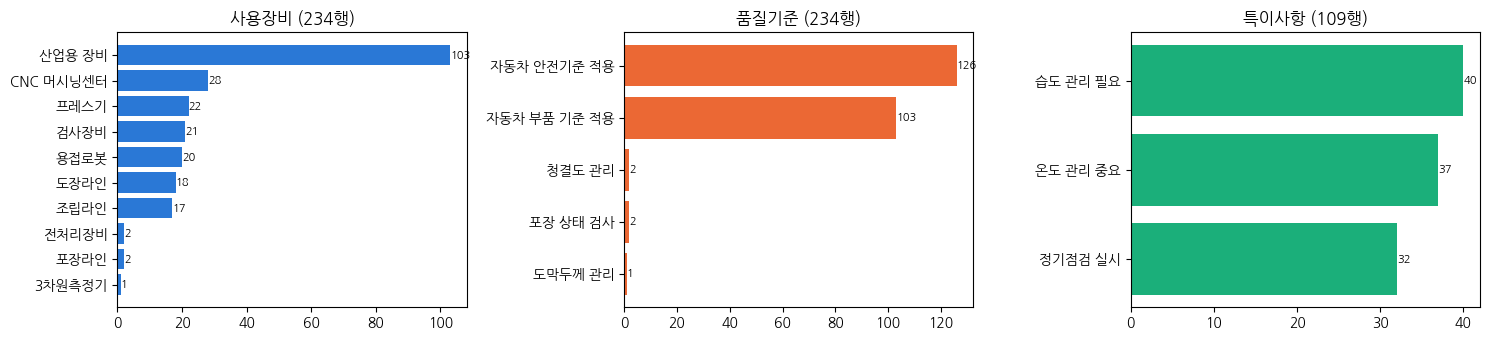

In [7]:
import matplotlib.pyplot as plt     # 그래프 그리는 도구
import koreanize_matplotlib         # 불러오기만 하면 그래프 한글 글꼴(나눔고딕)이 설정됨

# 그림 3칸 (사용장비, 품질기준, 특이사항)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, color in zip(axes, ["사용장비", "품질기준", "특이사항"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    counts = df[col].value_counts()                  # 값별 개수 (빈 칸은 자동으로 빠짐)
    ax.barh(counts.index, counts.values, color=color)
    ax.bar_label(ax.containers[0], fontsize=8)       # 막대 끝에 숫자 표시
    ax.invert_yaxis()                                # 많은 것부터 위에
    ax.set_title(f"{col} ({counts.sum()}행)")
plt.tight_layout()
plt.show()

✅ **결과 확인:**
- `산업용 장비`, `자동차 부품 기준 적용`처럼 **누구에게나 해당하는 말**이 가장 많습니다. 본문에 그대로 두었다면 `기준`, `적용`, `장비`가 상위 키워드를 차지했을 것입니다.
- 이 문구는 550행 중 일부에만 붙어 있고 표현이 몇 가지로 정해져 있어서, **자동으로 덧붙인 문구**로 보입니다(파일만으로는 확인할 수 없음).

---
## 3. 데이터 품질 점검
키워드 분석 전에, **글과 다른 열(공정명·공정도명)이 서로 맞는지** 확인합니다. 맞지 않으면 "업종별 키워드 비교" 같은 분석은 의미가 없습니다.

### 3-1. 공정명과 설명이 맞나요?

In [8]:
# 공정명이 짧은(잘리지 않은) 행 중 5개: 공정명과 설명 앞부분 비교
short = df[~df["공정명"].str.endswith("...") & df["사용장비"].isna()]    # ~: 아니다(not)
short[["공정명", "공정설명"]].sample(5, random_state=7)

,공정명,공정설명
209,침지도장,품질 검사 공정 검사된 제품에 대해 품질 및 성능검사 검사 후 검사라벨 부착하여 전용용기에 넣어 납품대기 한다. 협력사에서 생산된 부품을...
127,조립,조립 완제품 보관 및 납품 반제품으로 완성된 자동차용 휠 입고 입고된 스틸 프레스 품에 설계된 방식의 압출 공정 스틸 프레스 품에 트랙 ...
425,납땜,"납땜, 하우징 조립 및 하네스 작업 육안검사 및 검사기구 통한 검사 시트메카니즘과 버클, 인사이드커버 등 생산에 필요한 원재료 구매 입고..."
508,검사,출하검사 철판을 프레스를 이용해 부품형상으로 가공한다. 각 부품을 조립한다. 그라인더를 이용하여 표면을 매끄럽게 한다. 분체 도료로 색을...
249,중도도장,너트 용접 스틸 프레스 품에 지지용 브리짓 등을 용접하는 공정 스틸 프레스 품에 설계된 방식의 압출 공정 스틸 프레스 품에 설계된 방식의...


✅ **결과 확인:** `양극산화`, `스프레이도장` 같은 공정명 옆에 **전혀 다른 작업**(파이프 절단, 원단 봉제 등) 설명이 붙어 있나요? 한 행 안에 여러 제품의 설명 조각이 이어 붙은 경우도 많습니다.

### 3-2. 업종(공정도명)별 대표 키워드가 그 업종다운가요?
TF-IDF로 업종마다 **다른 업종보다 특히 많이 나온 키워드** 5개를 뽑아 봅니다. (절반이 넘는 업종에 공통으로 나오는 `검사`, `조립` 같은 키워드는 뺍니다.)

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 업종마다 키워드를 모두 이어 붙여 '업종 문서' 하나로 만들기 (groupby: 업종별로 묶기)
by_type = df.groupby("공정도명")["키워드문자열"].apply(" ".join)

# 업종 문서 25개로 TF-IDF
#   analyzer=str.split : 이미 나눠 둔 키워드 그대로
#   max_df=0.5         : 절반이 넘는 업종에 나오는 흔한 키워드(검사, 조립 …)는 빼기 → 업종마다 '특히 많은' 키워드만 남김
#   sublinear_tf=True  : 많이 나온 횟수를 log로 줄여서, 한 업종 안에서 몇 번 반복된 말이 지나치게 커지지 않게
tfidf_type = TfidfVectorizer(analyzer=str.split, max_df=0.5, sublinear_tf=True)
M = tfidf_type.fit_transform(by_type).toarray()          # (업종 수, 키워드 수) 숫자 표
names = tfidf_type.get_feature_names_out()                # 키워드 목록 (열 순서)

# 업종마다 점수가 큰 키워드 5개 (argsort()[::-1][:5]: 큰 순서로 위치 5개)
check = pd.DataFrame({"대표 키워드": [", ".join(names[row.argsort()[::-1][:5]]) for row in M]}, index=by_type.index)
check.head(8)

,대표 키워드
공정도명,
자동차 구동계통 부품 제조업 생산공정,"관리, 사이클, 헹거, 조작, 본체"
자동차 금속가공 부품 제조업 생산공정,"벌크, 트레일러, 배출구, lfi, 압력"
자동차 내장 부품 제조업 생산공정,"임펠러, 유동, 다음, 검출, 주행"
자동차 냉각시스템 부품 제조업 생산공정,"버튼, visi, 조명, 일반, 강철"
자동차 단조 부품 제조업 생산공정,"tpm, 버클, 인사이드, 콘덴서, 트럭"
자동차 동력전달 부품 제조업 생산공정,"의거, 트럭, 공업, 리팩토리군산, 수주"
자동차 배기시스템 부품 제조업 생산공정,"창원, 공작기계, gear, 불량품, 산업"
자동차 변속기 부품 제조업 생산공정,"part, 본딩, 협력, 파이프레이저, 정보"


✅ **결과 확인:** '냉각시스템 부품'에 `라디에이터`, `냉각수`가 아니라 `버튼`, `조명`이, '내장 부품'에 `시트`, `원단`이 아니라 `임펠러`가 나오나요? 업종다운 단어가 거의 보이지 않는다면, **업종 정보와 글이 따로 놀고 있다**는 뜻입니다.

> 💡 **결론:** 이 데이터에서는 업종별·공정 단계별 비교를 하지 않고, **전체 글을 하나로 보고** 키워드를 분석합니다. 실제 현장 데이터에서도 분석 전에 이런 점검이 꼭 필요합니다.

---
## 4. 키워드 분석
| 번호 | 분석 |
|---|---|
| 4-1 | 빈도 3종 비교: 등장 횟수 vs 문서 빈도 vs TF-IDF |
| 4-2 | 워드클라우드 |
| 4-3 | 2-gram: 붙어 나오는 두 키워드 |
| 4-4 | 공정 단계 사전으로 키워드 묶기 |
| 4-5 | 행별 대표 키워드 |

### 4-1. 빈도 3종 비교
| 방식 | 세는 법 | 장점 | 단점 |
|---|---|---|---|
| **등장 횟수** | 전체 글에서 나온 횟수 | 가장 단순 | 한 행 안에서 같은 구절이 반복되면 부풀려짐 |
| **문서 빈도** | 그 키워드가 나온 **행 수** | 반복에 강함 | 흔한 말이 위로 올라감 |
| **TF-IDF 합계** | 행마다 TF-IDF 점수를 구해 더함 | 흔한 말은 낮추고 **특징 있는 말**을 올림 | 숫자의 뜻을 설명하기 어려움 |

In [10]:
from collections import Counter     # 개수 세기 도구

# ① 등장 횟수: 모든 행의 키워드를 한 줄로 펼쳐서 세기
count_all = Counter(w for kws in df["키워드"] for w in kws)

# ② 문서 빈도: 행마다 set()으로 중복을 없앤 뒤 세기 → '몇 개 행에 나왔나'
count_doc = Counter(w for kws in df["키워드"] for w in set(kws))

# ③ TF-IDF 합계: 행 550개 각각을 문서로 보고 TF-IDF → 키워드별 점수를 모든 행에 걸쳐 더하기
tfidf = TfidfVectorizer(analyzer=str.split)
X = tfidf.fit_transform(df["키워드문자열"])                    # (행 수, 키워드 수) 점수 표
tfidf_sum = pd.Series(X.sum(axis=0).A1, index=tfidf.get_feature_names_out())   # .A1: 1줄짜리 배열로

# ✏️ 상위 몇 개를 볼지
TOP = 15

# 세 방식의 상위 키워드를 나란히 놓은 표 (most_common: 많은 순서로, nlargest: 큰 순서로)
compare = pd.DataFrame({
    "등장 횟수": [f"{w} ({n})" for w, n in count_all.most_common(TOP)],
    "문서 빈도(행 수)": [f"{w} ({n})" for w, n in count_doc.most_common(TOP)],
    "TF-IDF 합계": [f"{w} ({s:.1f})" for w, s in tfidf_sum.nlargest(TOP).items()],
}, index=range(1, TOP + 1))
compare

,등장 횟수,문서 빈도(행 수),TF-IDF 합계
1,검사 (982),검사 (377),검사 (51.0)
2,조립 (726),조립 (333),조립 (40.6)
3,원자재 (655),원자재 (330),가공 (38.1)
4,가공 (617),입고 (314),원자재 (37.8)
5,입고 (583),출하 (296),입고 (34.3)
6,포장 (477),가공 (287),포장 (30.5)
7,출하 (472),포장 (287),출하 (28.5)
8,성형 (308),납품 (187),성형 (25.3)
9,납품 (287),성형 (177),용접 (23.8)
10,용접 (276),용접 (160),납품 (22.8)


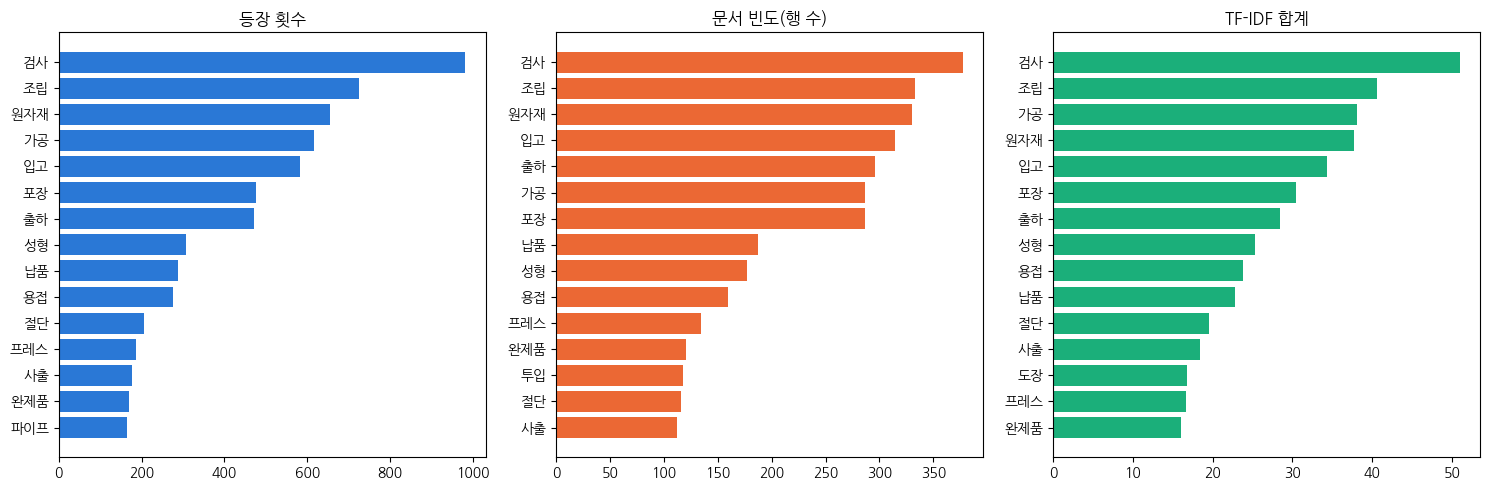

In [11]:
# 세 방식 상위 15개를 막대그래프 3칸으로
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
series_list = [pd.Series(dict(count_all.most_common(TOP))),        # 등장 횟수
               pd.Series(dict(count_doc.most_common(TOP))),        # 문서 빈도
               tfidf_sum.nlargest(TOP)]                            # TF-IDF 합계
for ax, s, title, color in zip(axes, series_list, compare.columns, ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.barh(s.index[::-1], s.values[::-1], color=color)            # [::-1]: 큰 값이 위로 오게 뒤집기
    ax.set_title(title)
plt.tight_layout()
plt.show()

✅ **결과 확인:**
- `검사`, `조립`, `입고`, `가공`, `포장`처럼 **제조 공정의 기본 단계**가 세 방식 모두에서 위에 있습니다.
- 등장 횟수에서는 위에 있는데 문서 빈도에서는 내려간 키워드가 있나요? **몇몇 행에서만 반복해서** 나온 말입니다.
- TF-IDF에서 순위가 오른 키워드는 **몇몇 행을 특히 잘 설명하는 말**입니다.

### 4-2. 워드클라우드
글자가 클수록 많이 나온 키워드입니다. 여기서는 **문서 빈도**를 씁니다.

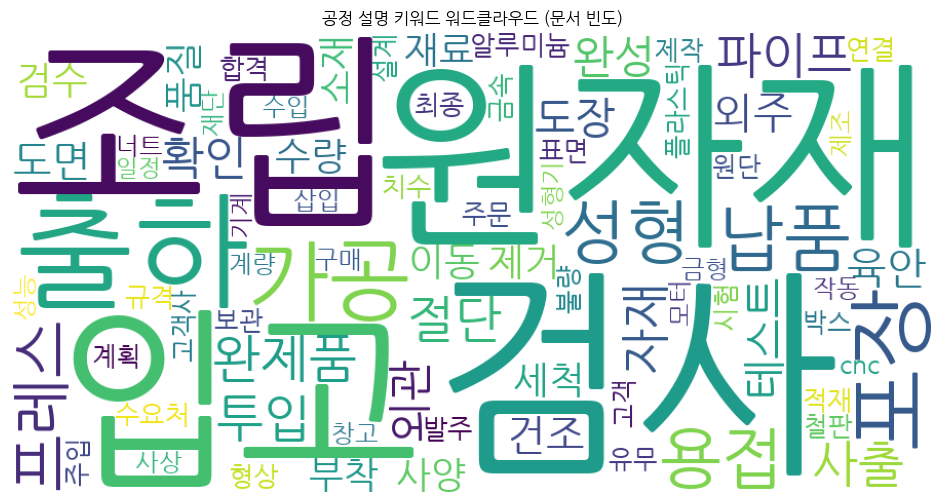

In [12]:
import os
from wordcloud import WordCloud

# koreanize_matplotlib 안에 들어 있는 나눔고딕 글꼴 파일 위치 (워드클라우드는 한글 글꼴 경로를 따로 알려 줘야 함)
font_path = os.path.join(os.path.dirname(koreanize_matplotlib.__file__), "fonts", "NanumGothic.ttf")

# 워드클라우드 만들기 (max_words: 최대 키워드 수, colormap: 색 묶음, random_state: 매번 같은 배치)
wc = WordCloud(font_path=font_path, width=900, height=450, background_color="white",
               max_words=80, colormap="viridis", random_state=42).generate_from_frequencies(count_doc)

plt.figure(figsize=(12, 6))
plt.imshow(wc)          # 그림으로 보여 주기
plt.axis("off")         # 눈금·테두리 숨기기
plt.title("공정 설명 키워드 워드클라우드 (문서 빈도)")
plt.show()

### 4-3. 2-gram: 붙어 나오는 두 키워드
`원자재` 하나보다 `원자재 입고`처럼 **두 단어 묶음**이 현장 작업을 더 구체적으로 보여 줍니다.
`CountVectorizer(ngram_range=(2, 2))`는 키워드 목록에서 **바로 옆에 붙은 두 키워드**를 한 묶음으로 셉니다.

> ⚠️ 이 데이터는 서로 다른 설명 조각이 이어 붙어 있어서, 조각과 조각 사이의 두 키워드는 **우연히 붙은 것**일 수 있습니다.

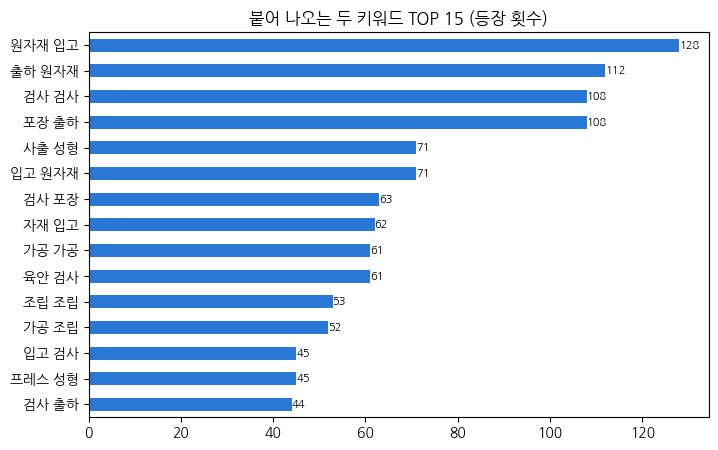

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

# 두 키워드 묶음 세기
#   analyzer=str.split 대신 token_pattern으로 '띄어쓰기로 나뉜 덩어리'를 한 단어로 봄
#   ngram_range=(2, 2) : 두 단어 묶음만
bigram = CountVectorizer(token_pattern=r"\S+", ngram_range=(2, 2))
B = bigram.fit_transform(df["키워드문자열"])
bigram_count = pd.Series(B.sum(axis=0).A1, index=bigram.get_feature_names_out()).nlargest(15)

# 가로 막대
ax = bigram_count[::-1].plot.barh(color="#2a78d6", figsize=(8, 5))
ax.bar_label(ax.containers[0], fontsize=8)
ax.set_title("붙어 나오는 두 키워드 TOP 15 (등장 횟수)")
plt.show()

✅ **결과 확인:**
- `원자재 입고`, `포장 출하`, `사출 성형`, `육안 검사`처럼 **작업 내용이 그대로 드러나는 묶음**이 보입니다. 이런 묶음은 공정 용어 사전을 만들 때 좋은 재료가 됩니다.
- `출하 원자재`는 한 조각의 끝(…출하)과 다음 조각의 시작(원자재 입고…)이 **우연히 붙은 묶음**입니다.
- `검사 검사`, `가공 가공`은 `검사 완료된 제품을 검사`처럼 같은 말이 가까이 반복되거나, 사이의 불용어가 빠지면서 붙은 묶음입니다.
- 이렇게 2-gram 결과도 **사람이 읽고 걸러야** 합니다.

### 4-4. 공정 단계 사전으로 키워드 묶기
**✏️ 공정 단계 사전 `STAGES`**: 키워드를 6개 공정 단계로 묶어, 공정 설명에 **어떤 단계가 얼마나 자주 언급되는지** 봅니다. 사전에 없는 키워드는 세지 않습니다.

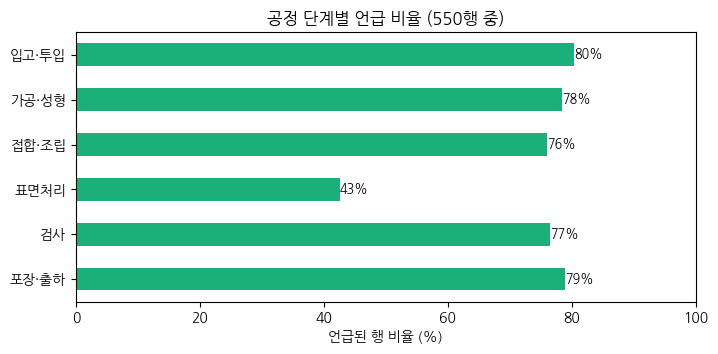

입고·투입 : 원자재(330), 입고(314), 투입(118)
가공·성형 : 가공(287), 성형(177), 프레스(135)
접합·조립 : 조립(333), 용접(160), 부착(64)
표면처리  : 도장(84), 건조(79), 세척(69)
검사    : 검사(377), 외관(88), 테스트(84)
포장·출하 : 출하(296), 포장(287), 납품(187)


In [14]:
# ✏️ 공정 단계 사전 {단계: [그 단계를 뜻하는 키워드들]}
STAGES = {
    "입고·투입": ["입고", "원자재", "자재", "투입", "계량", "발주", "조달"],
    "가공·성형": ["가공", "절단", "성형", "사출", "프레스", "절삭", "단조", "주조", "밴딩", "타발", "재단", "cnc"],
    "접합·조립": ["조립", "용접", "압입", "체결", "융착", "부착", "삽입", "장착"],
    "표면처리": ["도장", "세척", "건조", "도금", "탈지", "코팅", "열처리", "도포", "사상"],
    "검사": ["검사", "측정", "시험", "테스트", "외관", "검수", "육안", "불량"],
    "포장·출하": ["포장", "출하", "납품", "적재", "박스", "보관", "창고"],
}

# 단계별로 '그 단계 키워드가 하나라도 나온 행'의 비율(%) 계산
#   any(w in words for w in kws): 행의 키워드 중 하나라도 단계 사전에 있으면 True
stage_ratio = pd.Series({
    stage: df["키워드"].apply(lambda kws: any(w in words for w in kws)).mean() * 100
    for stage, words in STAGES.items()
})

# 가로 막대 (단계 순서대로 위에서 아래로)
ax = stage_ratio[::-1].plot.barh(color="#1baf7a", figsize=(8, 3.5), xlim=(0, 100))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=9)
ax.set_xlabel("언급된 행 비율 (%)")
ax.set_title("공정 단계별 언급 비율 (550행 중)")
plt.show()

# 단계마다 가장 많이 나온 키워드 3개 (문서 빈도 기준)
for stage, words in STAGES.items():
    top3 = sorted(words, key=lambda w: count_doc[w], reverse=True)[:3]
    print(f"{stage:6s}:", ", ".join(f"{w}({count_doc[w]})" for w in top3))

✅ **결과 확인:** 표면처리를 뺀 다섯 단계가 모두 **10행 중 8행 가까이**에 나옵니다. 제품이 무엇이든 '받아서 → 만들고 → 조립하고 → 검사하고 → 내보내는' 흐름은 같기 때문입니다. 반면 **표면처리**(도장·세척·건조 등)는 일부 공장에서만 하는 작업이라 비율이 절반에 못 미칩니다.

### 4-5. 행별 대표 키워드
4-1의 TF-IDF 점수 표 `X`에서 행마다 점수가 가장 큰 키워드 3개를 뽑으면, 긴 설명을 **키워드 3개로 요약**할 수 있습니다.

In [15]:
words = tfidf.get_feature_names_out()            # 키워드 목록 (X의 열 순서)

# 행 하나(TF-IDF 점수 줄) → 점수 큰 키워드 3개 (점수가 0인 키워드는 뺌)
def top_keywords(i, n=3):
    row = X[i].toarray()[0]                       # i번째 행의 점수 줄
    best = row.argsort()[::-1][:n]                # 점수 큰 순서로 위치 n개
    return ", ".join(words[j] for j in best if row[j] > 0)

# 무작위 5행: 문장 앞부분과 대표 키워드
sample = df.sample(5, random_state=3)
pd.DataFrame({"문장(앞부분)": sample["문장"].str[:70],
              "대표 키워드": [top_keywords(i) for i in sample.index]})

,문장(앞부분),대표 키워드
134,SPOT 용접 OP 압입 압입력 시험 OP GLASS WOOL 삽입 CAS 사용하여 압입하고 규격범위 내 존재하는지 확인하는,"압입, 내부, spot"
58,사출성형 외주 보관 및 포장 및 검수 및 출하 원자재 입고 원재료 입고 검사 백보 측정검사후 수입검사 기록일지에 작성하여 보관,"측정, 중요, 검사"
130,검사 포장 및 전기장치 연결 테스트 그리스 주입 및 출고 원재료 용해 및 포장 및 원재료 P P 를 찍어내어 자동차 범퍼의 모,"범퍼, 성형, 클립"
389,주조 주조,주조
192,COVER 스프링 및 가공 절곡 가공 외주 보관 및 건조 원소재 입고 출 고 원자 절단함 가공작업된 가공품과 헹거 등을 입고함,"금속, 절단, 헹거"


✅ **결과 확인:** 대표 키워드 3개만 보고 어떤 공정인지 짐작이 되나요? 여러 조각이 섞인 행은 대표 키워드도 서로 관계없어 보일 수 있습니다.

---
## 정리

### ✅ 한 줄 정리
**공정 설명 글에서 반복 문구를 따로 뽑아 내고 정제한 뒤, 명사 키워드를 등장 횟수·문서 빈도·TF-IDF로 비교하고, 2-gram과 공정 단계 사전으로 제조 현장의 작업 흐름을 살펴봤다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `process_keywords.csv` | 정제 데이터셋 (공장·공정 정보, 정제 문장, 키워드, 사용장비·품질기준·특이사항) |

### 🤔 생각해 볼 점 (한계)
| 한계 | 설명 |
|---|---|
| **글과 다른 열이 맞지 않음** | 업종·공정명과 설명이 따로 놀아서 업종별·단계별 비교를 할 수 없었습니다. 어떻게 이런 데이터가 만들어졌는지는 파일만으로는 알 수 없습니다. |
| **글이 잘려 있음** | 대부분의 설명이 `...`로 끝나서 뒷부분 키워드는 세지 못했습니다. |
| **무엇으로 세느냐에 따라 순위가 바뀜** | 등장 횟수·문서 빈도·TF-IDF 중 '정답'은 없습니다. 목적(많이 하는 작업 / 특징 있는 작업)에 맞게 고릅니다. |
| **불용어·사전은 사람이 정함** | `STOP`, `NORM`, `STAGES`를 바꾸면 결과도 바뀝니다. 분석자의 판단이 들어간다는 점을 결과와 함께 밝혀야 합니다. |
| **명사만 봄** | `절단한다`, `검사함` 같은 동사 표현은 명사(`절단`, `검사`)로 나뉠 때만 잡힙니다. |



**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [scikit-learn 텍스트 특징 추출](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [wordcloud](https://github.com/amueller/word_cloud)